# SAM2_Multimask_36
## Phase 1 — SAM2 multi-mask candidate-selection experiment

This notebook tests whether SAM2 sometimes produces a better mask candidate than the internally selected candidate.

The AgriCLIP → DINO → aligner → Top-K → automatic-box pipeline is kept fixed. Only the SAM2 multi-mask candidates are analysed.

**Important:** the ground-truth-based “oracle” candidate is diagnostic only. It is not a deployable method.

In [2]:
# CELL 1 — Imports
import os
import sys
import inspect
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from PIL import Image
from datasets import load_dataset
from torchvision import transforms
from tqdm.auto import tqdm

from transformers import Sam2Model, Sam2Processor

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA: True
Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [3]:
# CELL 2 — Configuration and paths
PROJECT_ROOT = Path("/home/zahranadeem/thesis")
MODEL_NAME = "facebook/sam2.1-hiera-tiny"

AGRICLIP_ROOT = PROJECT_ROOT / "agriclip_sam2" / "AgriCLIP"
ALIGNMENT_DIR = AGRICLIP_ROOT / "AgriCLIP_alignment"

ALIGNER_PATH = PROJECT_ROOT / "vegann_aligner.pth"
SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = PROJECT_ROOT / "results" / "SAM2_Multimask_36"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TOP_K = 32
BOX_MARGIN = 25
MASK_THRESHOLD = 0.5
SEED = 42

print("Aligner:", ALIGNER_PATH)
print("SAM2 checkpoint:", SAM2_CHECKPOINT)
print("Output:", OUTPUT_DIR)


Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2 checkpoint: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
Output: /home/zahranadeem/thesis/results/SAM2_Multimask_36


In [4]:
# CELL 3 — Load VegAnn and reproduce the validation split
vegann = load_dataset("simonMadec/VegAnn")

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=SEED,
)

train_hf = split["train"]
val_hf = split["test"]

columns = vegann["train"].column_names

IMAGE_KEY = next(
    x for x in columns
    if x in ["image", "images", "rgb"]
)

MASK_KEY = next(
    x for x in columns
    if x in ["mask", "masks", "label", "labels", "segmentation_mask"]
)

print("Train:", len(train_hf))
print("Validation:", len(val_hf))
print("IMAGE_KEY:", IMAGE_KEY)
print("MASK_KEY:", MASK_KEY)


Train: 3020
Validation: 755
IMAGE_KEY: image
MASK_KEY: mask


In [5]:
# CELL 4 — Image and mask helpers
def get_image(index, split=val_hf):
    sample = split[index]
    image = sample[IMAGE_KEY]

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    return image.convert("RGB")


def get_mask(index, split=val_hf):
    sample = split[index]
    mask = np.array(sample[MASK_KEY])
    return (mask > 0).astype(np.uint8)

print("Helpers ready.")


Helpers ready.


In [6]:
# CELL 5 — DINO preprocessing and model
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

dino_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for p in dino_model.parameters():
    p.requires_grad = False

print("DINO loaded.")


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/.local/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/.local/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO loaded.


In [7]:
# CELL 6 — Load AgriCLIP TextToConcept and LinearAligner
ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("AgriCLIP aligner loaded.")
print("W:", tuple(aligner.W.shape))
print("b:", tuple(aligner.b.shape))


AgriCLIP aligner loaded.
W: (512, 2048)
b: (512,)


In [8]:
# CELL 7 — DINO layer4 spatial features
captured_feature_map = None

def capture_layer4_output(module, inputs, output):
    global captured_feature_map
    captured_feature_map = output.detach()

hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

@torch.no_grad()
def extract_dino_patch_features(pil_image):
    global captured_feature_map

    captured_feature_map = None

    image_tensor = (
        dino_transform(pil_image)
        .unsqueeze(0)
        .to(device)
    )

    _ = dino_model(image_tensor)

    if captured_feature_map is None:
        raise RuntimeError("DINO layer4 hook captured no feature map.")

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            f"Expected (B,C,H,W), got {captured_feature_map.shape}"
        )

    _, channels, grid_h, grid_w = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(grid_h * grid_w, channels)
        .contiguous()
    )

    return patch_features, grid_h, grid_w

print("DINO spatial extractor ready.")


DINO spatial extractor ready.


In [9]:
# CELL 8 — Vegetation text prompts and encoding
POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil
Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])
Final vegetation embedding: torch.Size([512])


In [10]:
# CELL 9 — Align DINO patches into AgriCLIP concept space
@torch.no_grad()
def align_patch_features(patch_features):
    patch_features = patch_features.float().to(device)

    aligned_features = aligner.get_aligned_representation(
        patch_features
    )

    return F.normalize(aligned_features, dim=1)

print("Patch aligner ready.")


Patch aligner ready.


In [11]:
# CELL 10 — Generate the fixed AgriCLIP automatic box
@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k=TOP_K,
    margin=BOX_MARGIN,
):
    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(image)
    )

    aligned_features = align_patch_features(
        patch_features
    )

    patch_scores = aligned_features @ vegetation_embedding
    scores = patch_scores.detach().cpu().numpy()

    top_k = min(int(top_k), len(scores))
    topk_indices = np.argsort(scores)[::-1][:top_k]

    H, W = image.size[1], image.size[0]

    patch_h = H / grid_h
    patch_w = W / grid_w

    boxes = []

    for idx in topk_indices:
        r = int(idx) // grid_w
        c = int(idx) % grid_w

        x1 = int(c * patch_w)
        y1 = int(r * patch_h)
        x2 = int((c + 1) * patch_w)
        y2 = int((r + 1) * patch_h)

        boxes.append([x1, y1, x2, y2])

    boxes = np.asarray(boxes, dtype=np.int32)

    xmin = max(0, int(boxes[:, 0].min()) - margin)
    ymin = max(0, int(boxes[:, 1].min()) - margin)
    xmax = min(W - 1, int(boxes[:, 2].max()) + margin)
    ymax = min(H - 1, int(boxes[:, 3].max()) + margin)

    merged_box = np.array(
        [xmin, ymin, xmax, ymax],
        dtype=np.int32,
    )

    return (
        merged_box,
        boxes,
        scores,
        topk_indices,
        grid_h,
        grid_w,
    )

print(inspect.signature(generate_agriclip_box))


(image, top_k=32, margin=25)


In [12]:
# CELL 11 — Load the existing VegAnn-fine-tuned SAM2 decoder
sam2_processor = Sam2Processor.from_pretrained(MODEL_NAME)
sam2_model = Sam2Model.from_pretrained(MODEL_NAME)

checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
)

print("Checkpoint type:", type(checkpoint))

if (
    isinstance(checkpoint, dict)
    and "mask_decoder_state_dict" in checkpoint
):
    decoder_state = checkpoint["mask_decoder_state_dict"]
else:
    decoder_state = checkpoint

load_result = sam2_model.mask_decoder.load_state_dict(
    decoder_state,
    strict=True,
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("Fine-tuned SAM2 decoder loaded.")
print(load_result)



[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Checkpoint type: <class 'dict'>
Fine-tuned SAM2 decoder loaded.
<All keys matched successfully>


In [13]:
# CELL 12 — Multi-mask SAM2 inference
@torch.no_grad()
def sam2_predict_multimask(
    image,
    input_box,
    threshold=MASK_THRESHOLD,
):
    sam2_inputs = sam2_processor(
        images=image,
        input_boxes=[[input_box.tolist()]],
        return_tensors="pt",
    )

    sam2_inputs = {
        k: v.to(device) if torch.is_tensor(v) else v
        for k, v in sam2_inputs.items()
    }

    outputs = sam2_model(**sam2_inputs)

    logits = outputs.pred_masks[0, 0]
    scores = outputs.iou_scores[0, 0]

    original_height = int(
        sam2_inputs["original_sizes"][0, 0].item()
    )
    original_width = int(
        sam2_inputs["original_sizes"][0, 1].item()
    )

    probabilities = F.interpolate(
        torch.sigmoid(logits).unsqueeze(1),
        size=(original_height, original_width),
        mode="bilinear",
        align_corners=False,
    ).squeeze(1)

    candidate_masks = (
        probabilities >= threshold
    ).detach().cpu().numpy().astype(np.uint8)

    candidate_probabilities = probabilities.detach().cpu().numpy()
    candidate_scores = scores.detach().cpu().numpy()

    default_candidate = int(np.argmax(candidate_scores))

    return {
        "candidate_masks": candidate_masks,
        "candidate_probabilities": candidate_probabilities,
        "candidate_scores": candidate_scores,
        "default_candidate": default_candidate,
        "default_mask": candidate_masks[default_candidate],
        "default_probability": candidate_probabilities[default_candidate],
        "default_confidence": float(candidate_scores[default_candidate]),
    }

print(inspect.signature(sam2_predict_multimask))


(image, input_box, threshold=0.5)


In [14]:
# CELL 13 — Metrics
def compute_binary_metrics(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(
        prediction,
        ground_truth,
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth,
    ).sum()

    pred_pixels = prediction.sum()
    gt_pixels = ground_truth.sum()

    iou = intersection / union if union > 0 else 1.0

    denominator = pred_pixels + gt_pixels
    dice = (
        2.0 * intersection / denominator
        if denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
    }

print("Metrics ready.")


Metrics ready.


In [15]:
# CELL 14 — Single-image diagnostic
sample_index = 0

image = get_image(sample_index)
gt_mask = get_mask(sample_index)

(
    agriclip_box,
    patch_boxes,
    patch_scores,
    topk_indices,
    grid_h,
    grid_w,
) = generate_agriclip_box(
    image,
    top_k=TOP_K,
    margin=BOX_MARGIN,
)

multi = sam2_predict_multimask(
    image,
    agriclip_box,
    threshold=MASK_THRESHOLD,
)

print("=" * 70)
print("SINGLE IMAGE MULTI-MASK DIAGNOSTIC")
print("=" * 70)
print("Image:", sample_index)
print("Image size:", image.size)
print("AgriCLIP box:", agriclip_box)
print("Top-K:", TOP_K)
print("Feature grid:", f"{grid_h} x {grid_w}")
print("Number of SAM2 candidates:", len(multi["candidate_scores"]))
print("Candidate confidence:", multi["candidate_scores"])
print("Default selected candidate:", multi["default_candidate"])

for i, mask in enumerate(multi["candidate_masks"]):
    m = compute_binary_metrics(mask, gt_mask)
    print(
        f"Candidate {i}: "
        f"confidence={multi['candidate_scores'][i]:.4f} | "
        f"IoU={m['iou']*100:.2f}% | "
        f"Dice={m['dice']*100:.2f}% | "
        f"Precision={m['precision']*100:.2f}% | "
        f"Recall={m['recall']*100:.2f}%"
    )


SINGLE IMAGE MULTI-MASK DIAGNOSTIC
Image: 0
Image size: (512, 512)
AgriCLIP box: [  0   0 511 511]
Top-K: 32
Feature grid: 7 x 7
Number of SAM2 candidates: 3
Candidate confidence: [0.93143666 0.6524526  0.95244384]
Default selected candidate: 2
Candidate 0: confidence=0.9314 | IoU=90.18% | Dice=94.84% | Precision=92.72% | Recall=97.06%
Candidate 1: confidence=0.6525 | IoU=87.19% | Dice=93.15% | Precision=96.96% | Recall=89.63%
Candidate 2: confidence=0.9524 | IoU=90.22% | Dice=94.86% | Precision=94.79% | Recall=94.92%


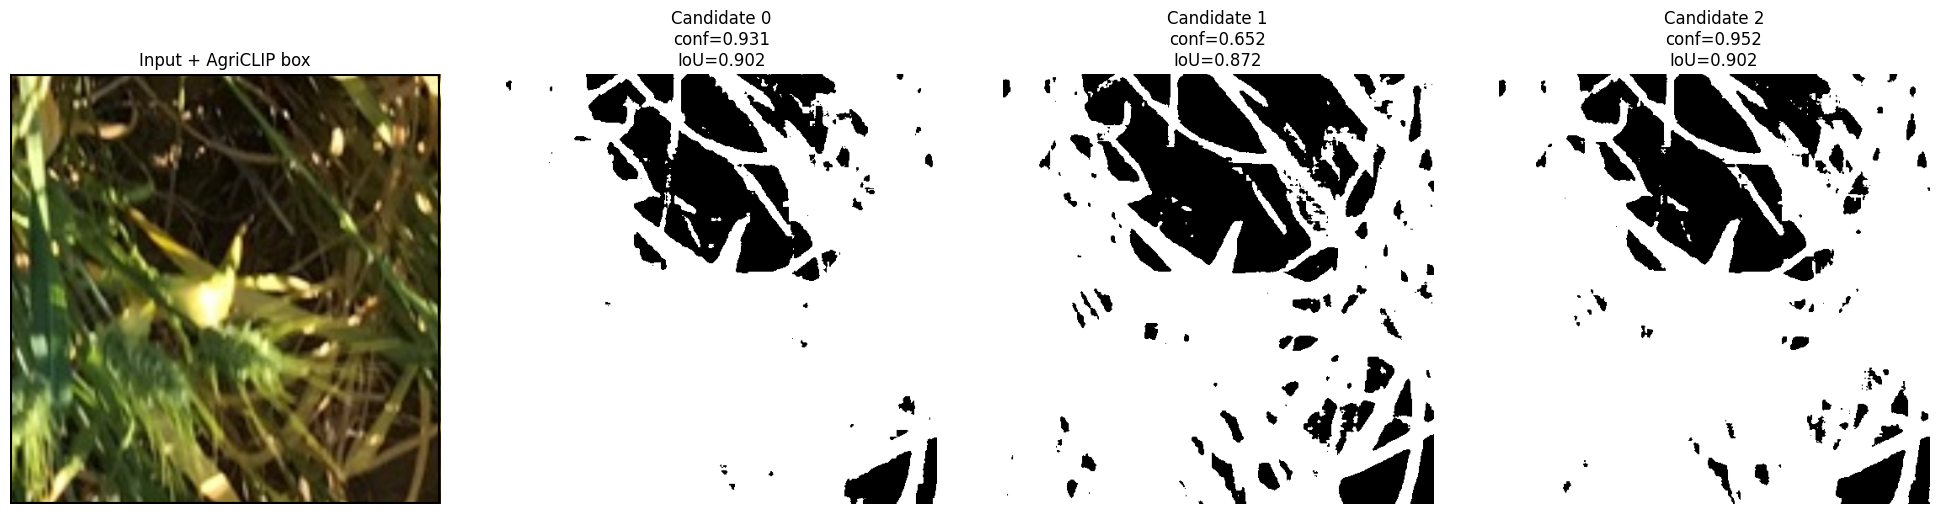

In [16]:
# CELL 15 — Visualize all candidate masks
candidate_masks = multi["candidate_masks"]
candidate_scores = multi["candidate_scores"]

n = len(candidate_masks)

fig, axes = plt.subplots(
    1,
    n + 1,
    figsize=(5 * (n + 1), 5),
)

axes = np.atleast_1d(axes)

axes[0].imshow(image)
axes[0].add_patch(
    plt.Rectangle(
        (agriclip_box[0], agriclip_box[1]),
        agriclip_box[2] - agriclip_box[0],
        agriclip_box[3] - agriclip_box[1],
        fill=False,
        linewidth=3,
    )
)
axes[0].set_title("Input + AgriCLIP box")
axes[0].axis("off")

for i in range(n):
    axes[i + 1].imshow(candidate_masks[i], cmap="gray")
    m = compute_binary_metrics(candidate_masks[i], gt_mask)
    axes[i + 1].set_title(
        f"Candidate {i}\n"
        f"conf={candidate_scores[i]:.3f}\n"
        f"IoU={m['iou']:.3f}"
    )
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()


In [17]:
# CELL 16 — Candidate-level comparison
def evaluate_candidates(
    candidate_masks,
    candidate_scores,
    gt_mask,
):
    rows = []

    for i, mask in enumerate(candidate_masks):
        metrics = compute_binary_metrics(
            mask,
            gt_mask,
        )

        rows.append({
            "candidate": i,
            "sam2_confidence": float(candidate_scores[i]),
            **metrics,
        })

    df = pd.DataFrame(rows)

    default_idx = int(np.argmax(candidate_scores))
    oracle_idx = int(df["iou"].idxmax())

    return (
        df,
        default_idx,
        oracle_idx,
        df.iloc[default_idx],
        df.iloc[oracle_idx],
    )

(
    candidate_df,
    default_idx,
    oracle_idx,
    default_metrics,
    oracle_metrics,
) = evaluate_candidates(
    multi["candidate_masks"],
    multi["candidate_scores"],
    gt_mask,
)

print(candidate_df)
print("\nDefault candidate:")
print(default_metrics)
print("\nOracle-best-IoU candidate:")
print(oracle_metrics)
print(
    "\nOracle improvement:",
    f"{(oracle_metrics['iou'] - default_metrics['iou']) * 100:.2f} pp",
)


   candidate  sam2_confidence       iou      dice  precision    recall
0          0         0.931437  0.901834  0.948384   0.927150  0.970613
1          1         0.652453  0.871855  0.931541   0.969640  0.896323
2          2         0.952444  0.902177  0.948573   0.947917  0.949230

Default candidate:
candidate          2.000000
sam2_confidence    0.952444
iou                0.902177
dice               0.948573
precision          0.947917
recall             0.949230
Name: 2, dtype: float64

Oracle-best-IoU candidate:
candidate          2.000000
sam2_confidence    0.952444
iou                0.902177
dice               0.948573
precision          0.947917
recall             0.949230
Name: 2, dtype: float64

Oracle improvement: 0.00 pp


In [18]:
# CELL 17 — Full 746-image validation experiment
multimask_results = []
candidate_records = []

for idx in tqdm(
    range(len(val_hf)),
    desc="Evaluating VegAnn",
):
    try:
        image = get_image(idx)
        gt_mask = get_mask(idx)

        # Same protocol as the established VegAnn result:
        # exclude empty-GT images.
        if gt_mask.sum() == 0:
            continue

        agriclip_box = generate_agriclip_box(
            image,
            top_k=TOP_K,
            margin=BOX_MARGIN,
        )[0]

        multi = sam2_predict_multimask(
            image,
            agriclip_box,
            threshold=MASK_THRESHOLD,
        )

        (
            candidate_df,
            default_idx,
            oracle_idx,
            default_metrics,
            oracle_metrics,
        ) = evaluate_candidates(
            multi["candidate_masks"],
            multi["candidate_scores"],
            gt_mask,
        )

        multimask_results.append({
            "image_index": idx,
            "default_candidate": default_idx,
            "oracle_candidate": oracle_idx,
            "default_confidence": float(
                default_metrics["sam2_confidence"]
            ),
            "default_iou": float(default_metrics["iou"]),
            "default_dice": float(default_metrics["dice"]),
            "default_precision": float(default_metrics["precision"]),
            "default_recall": float(default_metrics["recall"]),
            "oracle_iou": float(oracle_metrics["iou"]),
            "oracle_dice": float(oracle_metrics["dice"]),
            "oracle_precision": float(oracle_metrics["precision"]),
            "oracle_recall": float(oracle_metrics["recall"]),
            "oracle_gain_iou": float(
                oracle_metrics["iou"] - default_metrics["iou"]
            ),
            "num_candidates": len(multi["candidate_scores"]),
        })

        for row in candidate_df.to_dict("records"):
            row["image_index"] = idx
            candidate_records.append(row)

    except Exception as exc:
        print(
            f"Skipping image {idx}: "
            f"{type(exc).__name__}: {exc}"
        )

multimask_df = pd.DataFrame(multimask_results)
candidate_all_df = pd.DataFrame(candidate_records)

print("Successful images:", len(multimask_df))
print("Candidate records:", len(candidate_all_df))


Evaluating VegAnn:   0%|          | 0/755 [00:00<?, ?it/s]

Successful images: 746
Candidate records: 2238


In [19]:
# CELL 18 — Final summary
if len(multimask_df) == 0:
    raise RuntimeError("No validation results were produced.")

print("=" * 70)
print("SAM2 MULTI-MASK FINAL RESULTS")
print("=" * 70)

default_iou = multimask_df["default_iou"].mean()
oracle_iou = multimask_df["oracle_iou"].mean()

default_dice = multimask_df["default_dice"].mean()
oracle_dice = multimask_df["oracle_dice"].mean()

default_precision = multimask_df["default_precision"].mean()
oracle_precision = multimask_df["oracle_precision"].mean()

default_recall = multimask_df["default_recall"].mean()
oracle_recall = multimask_df["oracle_recall"].mean()

mean_gain = multimask_df["oracle_gain_iou"].mean()

print(f"Images evaluated:          {len(multimask_df)}")
print(f"Default mean IoU:          {default_iou*100:.2f}%")
print(f"Oracle mean IoU:           {oracle_iou*100:.2f}%")
print(f"Default mean Dice:         {default_dice*100:.2f}%")
print(f"Oracle mean Dice:          {oracle_dice*100:.2f}%")
print(f"Default mean Precision:    {default_precision*100:.2f}%")
print(f"Oracle mean Precision:     {oracle_precision*100:.2f}%")
print(f"Default mean Recall:       {default_recall*100:.2f}%")
print(f"Oracle mean Recall:        {oracle_recall*100:.2f}%")
print(f"Mean oracle IoU gain:      {mean_gain*100:.2f} pp")

better_fraction = (
    multimask_df["oracle_gain_iou"] > 1e-9
).mean() * 100

print(
    f"Images where another candidate is better: "
    f"{better_fraction:.2f}%"
)


SAM2 MULTI-MASK FINAL RESULTS
Images evaluated:          746
Default mean IoU:          85.04%
Oracle mean IoU:           86.33%
Default mean Dice:         91.17%
Oracle mean Dice:          92.08%
Default mean Precision:    90.09%
Oracle mean Precision:     90.79%
Default mean Recall:       93.41%
Oracle mean Recall:        94.07%
Mean oracle IoU gain:      1.29 pp
Images where another candidate is better: 57.77%


Candidate-level SAM2 confidence ↔ actual GT IoU: 0.5219


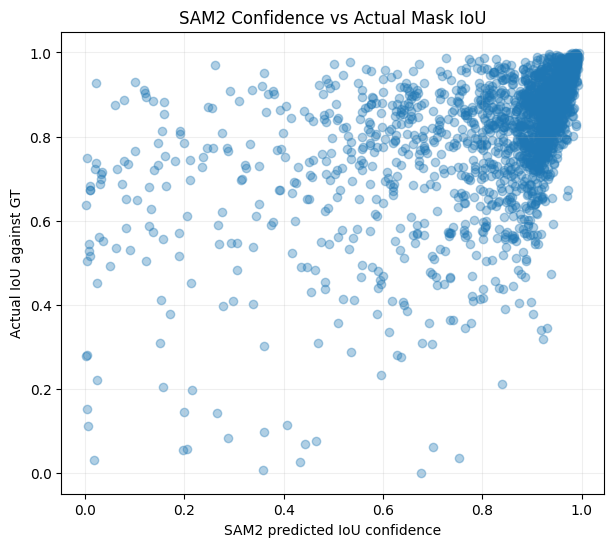

In [20]:
# CELL 19 — Does SAM2 confidence identify the correct candidate?
confidence_iou_corr = (
    candidate_all_df[
        ["sam2_confidence", "iou"]
    ]
    .corr()
    .loc["sam2_confidence", "iou"]
)

print(
    "Candidate-level SAM2 confidence ↔ actual GT IoU:",
    f"{confidence_iou_corr:.4f}"
)

plt.figure(figsize=(7, 6))
plt.scatter(
    candidate_all_df["sam2_confidence"],
    candidate_all_df["iou"],
    alpha=0.35,
)
plt.xlabel("SAM2 predicted IoU confidence")
plt.ylabel("Actual IoU against GT")
plt.title("SAM2 Confidence vs Actual Mask IoU")
plt.grid(True, alpha=0.2)
plt.show()


In [21]:
# CELL 20 — Candidate-selection agreement
selection_table = pd.crosstab(
    multimask_df["default_candidate"],
    multimask_df["oracle_candidate"],
)

print("Default candidate vs oracle candidate:")
print(selection_table)

agreement = (
    multimask_df["default_candidate"]
    == multimask_df["oracle_candidate"]
).mean() * 100

print(
    f"Default and oracle candidate agree on: {agreement:.2f}% of images"
)


Default candidate vs oracle candidate:
oracle_candidate     0    1    2
default_candidate               
0                  132   10   34
1                    4   22   11
2                  192  180  161
Default and oracle candidate agree on: 42.23% of images


In [22]:
# CELL 21 — Save all results
multimask_csv = OUTPUT_DIR / "multimask_results.csv"
candidate_csv = OUTPUT_DIR / "candidate_level_results.csv"

multimask_df.to_csv(
    multimask_csv,
    index=False,
)

candidate_all_df.to_csv(
    candidate_csv,
    index=False,
)

summary_path = OUTPUT_DIR / "multimask_summary.txt"

with open(summary_path, "w", encoding="utf-8") as f:
    f.write("SAM2 MULTI-MASK EXPERIMENT\n")
    f.write("=" * 70 + "\n")
    f.write(f"Images evaluated: {len(multimask_df)}\n")
    f.write(f"Top-K: {TOP_K}\n")
    f.write(f"Box margin: {BOX_MARGIN}\n")
    f.write(f"Mask threshold: {MASK_THRESHOLD}\n\n")
    f.write(f"Default mean IoU: {default_iou:.6f}\n")
    f.write(f"Oracle mean IoU: {oracle_iou:.6f}\n")
    f.write(f"Default mean Dice: {default_dice:.6f}\n")
    f.write(f"Oracle mean Dice: {oracle_dice:.6f}\n")
    f.write(f"Mean oracle IoU gain: {mean_gain:.6f}\n")
    f.write(
        f"Confidence/actual IoU correlation: "
        f"{confidence_iou_corr:.6f}\n"
    )
    f.write(
        f"Default/oracle agreement: "
        f"{agreement:.6f}\n"
    )

print("Saved:")
print(multimask_csv)
print(candidate_csv)
print(summary_path)


Saved:
/home/zahranadeem/thesis/results/SAM2_Multimask_36/multimask_results.csv
/home/zahranadeem/thesis/results/SAM2_Multimask_36/candidate_level_results.csv
/home/zahranadeem/thesis/results/SAM2_Multimask_36/multimask_summary.txt
